# Vessel classification from passive sonar — CNN vs PANNs, mixed-scenario training

**Research question:** does transfer learning from AudioSet (PANNs CNN14) beat a small CNN trained from scratch at classifying vessel types from 1-second passive sonar clips — and does any advantage survive at different distances (VTUAD scenarios S1/S2/S3) or on a completely different dataset (DeepShip)?

**This notebook:** for each model, compare the milestone version (trained on S1 only) against a new version trained on all three distance scenarios pooled. Every model is tested on the same unseen data: clean S1/S2/S3 test sets + DeepShip.

**Before running: Runtime -> Change runtime type -> T4 GPU -> Save.**

## Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
DRIVE_PROJECT_PATH = "/content/drive/MyDrive/sonar_project"
need = ["sonar.py", "Cnn14_mAP=0.431.pth",
        "models/cnn_scratch_nfull_s0_inclusion_2000_exclusion_4000.pt",
        "models/panns_ft-last2_n4000_s0_inclusion_2000_exclusion_4000.pt"]
for f in need:
    print(("OK       " if os.path.exists(os.path.join(DRIVE_PROJECT_PATH, f)) else "MISSING  ") + f)
print("cache files:", len(os.listdir(os.path.join(DRIVE_PROJECT_PATH, "cache"))), "(should be 13)")

OK       sonar.py
OK       Cnn14_mAP=0.431.pth
OK       models/cnn_scratch_nfull_s0_inclusion_2000_exclusion_4000.pt
OK       models/panns_ft-last2_n4000_s0_inclusion_2000_exclusion_4000.pt
cache files: 13 (should be 13)


In [3]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE - switch runtime to T4 GPU")

CUDA available: True
GPU: Tesla T4


In [4]:
# Copy everything to local disk (reading big files straight off Drive is slow), install PANNs' model code.
!pip install -q panns_inference
!mkdir -p /content/local_project/models /content/local_project/results
!cp -r "{DRIVE_PROJECT_PATH}/cache" /content/local_project/
!cp "{DRIVE_PROJECT_PATH}/sonar.py" "{DRIVE_PROJECT_PATH}/Cnn14_mAP=0.431.pth" /content/local_project/
!cp "{DRIVE_PROJECT_PATH}/models/cnn_scratch_nfull_s0_inclusion_2000_exclusion_4000.pt" /content/local_project/models/
!cp "{DRIVE_PROJECT_PATH}/models/panns_ft-last2_n4000_s0_inclusion_2000_exclusion_4000.pt" /content/local_project/models/
os.chdir("/content/local_project")
print("cwd:", os.getcwd(), "| models:", sorted(os.listdir("models")))

cwd: /content/local_project | models: ['cnn_scratch_nfull_s0_inclusion_2000_exclusion_4000.pt', 'panns_ft-last2_n4000_s0_inclusion_2000_exclusion_4000.pt']


## Part A — Scratch CNN (93,765 parameters)
**A1.** Milestone CNN, trained on S1 only (36,510 clips). No training here — just testing it on every test set.

In [5]:
!python sonar.py eval --model_file models/cnn_scratch_nfull_s0_inclusion_2000_exclusion_4000.pt \
  --eval_on inclusion_2000_exclusion_4000-clean inclusion_3000_exclusion_5000-clean inclusion_4000_exclusion_6000-clean deepship

TEST on inclusion_2000_exclusion_4000-clean: macro-F1 0.7728  acc 0.8877  -> results/cnn_scratch_nfull_s0_inclusion_2000_exclusion_4000__on_inclusion_2000_exclusion_4000-clean.json
TEST on inclusion_3000_exclusion_5000-clean: macro-F1 0.5303  acc 0.6772  -> results/cnn_scratch_nfull_s0_inclusion_2000_exclusion_4000__on_inclusion_3000_exclusion_5000-clean.json
TEST on inclusion_4000_exclusion_6000-clean: macro-F1 0.4641  acc 0.6605  -> results/cnn_scratch_nfull_s0_inclusion_2000_exclusion_4000__on_inclusion_4000_exclusion_6000-clean.json
TEST on deepship: macro-F1 0.2847  acc 0.3206  recording-vote acc 0.317  -> results/cnn_scratch_nfull_s0_inclusion_2000_exclusion_4000__on_deepship.json


**A2.** New CNN, trained on S1+S2+S3 pooled (8,000 clips per scenario = 24,000). 15 epochs, ~3 minutes on a T4. Then tested on the same sets.

In [6]:
!python sonar.py train --scenario inclusion_2000_exclusion_4000 inclusion_3000_exclusion_5000 inclusion_4000_exclusion_6000 \
  --model cnn --epochs 15 --max_train 24000 --overwrite \
  --eval_on inclusion_2000_exclusion_4000-clean inclusion_3000_exclusion_5000-clean inclusion_4000_exclusion_6000-clean deepship

device cuda
run cnn_scratch_n24000_s0_s1+s2+s3 | train 24000 [4772, 4729, 4970, 4740, 4789] | val 15770
[scratch] trainable parameters: 93,765
[scratch] ep 1/15 loss 1.1285 val macroF1 0.2468 (13s)
[scratch] ep 2/15 loss 0.9325 val macroF1 0.5488 (9s)
[scratch] ep 3/15 loss 0.8586 val macroF1 0.5592 (9s)
[scratch] ep 4/15 loss 0.8216 val macroF1 0.5154 (9s)
[scratch] ep 5/15 loss 0.7776 val macroF1 0.5022 (9s)
[scratch] ep 6/15 loss 0.7559 val macroF1 0.5726 (10s)
[scratch] ep 7/15 loss 0.7290 val macroF1 0.6147 (9s)
[scratch] ep 8/15 loss 0.7033 val macroF1 0.6651 (10s)
[scratch] ep 9/15 loss 0.6840 val macroF1 0.6320 (10s)
[scratch] ep 10/15 loss 0.6622 val macroF1 0.6819 (10s)
[scratch] ep 11/15 loss 0.6489 val macroF1 0.6804 (10s)
[scratch] ep 12/15 loss 0.6341 val macroF1 0.6531 (10s)
[scratch] ep 13/15 loss 0.6212 val macroF1 0.6819 (10s)
[scratch] ep 14/15 loss 0.6127 val macroF1 0.6940 (10s)
[scratch] ep 15/15 loss 0.6086 val macroF1 0.7042 (10s)
saved models/cnn_scratch_n24000

## Part B — PANNs CNN14 transfer learning (81.8M-parameter backbone, pretrained on AudioSet)
**B1.** Milestone PANNs, fine-tuned on S1 only (4,000 clips). No training here — just testing.

In [7]:
!python sonar.py eval --model_file models/panns_ft-last2_n4000_s0_inclusion_2000_exclusion_4000.pt \
  --eval_on inclusion_2000_exclusion_4000-clean inclusion_3000_exclusion_5000-clean inclusion_4000_exclusion_6000-clean deepship

--2026-11-10 23:13:24--  http://storage.googleapis.com/us_audioset/youtube_corpus/v1/csv/class_labels_indices.csv
Resolving storage.googleapis.com (storage.googleapis.com)... 74.125.137.207, 142.251.2.207, 2600:1901:4021:1b00::, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|74.125.137.207|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 14675 (14K) [application/octet-stream]
Saving to: ‘/root/panns_data/class_labels_indices.csv’

/root/panns_data/cl 100%[===================>]  14.33K  --.-KB/s    in 0s      

2026-11-10 23:13:24 (36.9 MB/s) - ‘/root/panns_data/class_labels_indices.csv’ saved [14675/14675]

TEST on inclusion_2000_exclusion_4000-clean: macro-F1 0.4279  acc 0.5764  -> results/panns_ft-last2_n4000_s0_inclusion_2000_exclusion_4000__on_inclusion_2000_exclusion_4000-clean.json
TEST on inclusion_3000_exclusion_5000-clean: macro-F1 0.3915  acc 0.5138  -> results/panns_ft-last2_n4000_s0_inclusion_2000_exclusion_4000__on_inclusion_3000_

**B2.** New PANNs, fine-tuned on S1+S2+S3 pooled (24,000 clips). Same two-stage recipe as the milestone (batch size 64 here, 16 at the milestone): 3 epochs training only the new classifier head (CNN14 frozen), then 3 epochs also fine-tuning CNN14's last two conv blocks at a 20x lower learning rate. about 6 minutes on a T4 (6.4 minutes measured).

In [8]:
!python sonar.py train --scenario inclusion_2000_exclusion_4000 inclusion_3000_exclusion_5000 inclusion_4000_exclusion_6000 \
  --model panns --ckpt "Cnn14_mAP=0.431.pth" \
  --epochs 6 --freeze_epochs 3 --unfreeze last2 --max_train 24000 --overwrite \
  --eval_on inclusion_2000_exclusion_4000-clean inclusion_3000_exclusion_5000-clean inclusion_4000_exclusion_6000-clean deepship

device cuda
run panns_ft-last2_n24000_s0_s1+s2+s3 | train 24000 [4772, 4729, 4970, 4740, 4789] | val 15770
PANNs weights loaded OK: 84 tensors from Cnn14_mAP=0.431.pth (missing=0, unexpected=0)
[head_only] trainable parameters: 10,245
[head_only] ep 1/3 loss 1.5100 val macroF1 0.3841 (52s)
[head_only] ep 2/3 loss 1.4560 val macroF1 0.3959 (49s)
[head_only] ep 3/3 loss 1.4368 val macroF1 0.3516 (48s)
[unfrozen-last2] trainable parameters: 74,997,765
[unfrozen-last2] ep 1/3 loss 1.4569 val macroF1 0.4693 (75s)
[unfrozen-last2] ep 2/3 loss 1.2706 val macroF1 0.5022 (75s)
[unfrozen-last2] ep 3/3 loss 1.2011 val macroF1 0.5205 (75s)
saved models/panns_ft-last2_n24000_s0_s1+s2+s3.pt (best epoch 6, val macro-F1 0.5205)
TEST on inclusion_2000_exclusion_4000-clean: macro-F1 0.4571  acc 0.5912  -> results/panns_ft-last2_n24000_s0_s1+s2+s3__on_inclusion_2000_exclusion_4000-clean.json
TEST on inclusion_3000_exclusion_5000-clean: macro-F1 0.5020  acc 0.6080  -> results/panns_ft-last2_n24000_s0_s1+s

## Results — macro-F1 on every test set

In [9]:
import json
runs = [("CNN    S1 only (milestone)",  "cnn_scratch_nfull_s0_inclusion_2000_exclusion_4000"),
        ("CNN    S1+S2+S3 (new)",       "cnn_scratch_n24000_s0_s1+s2+s3"),
        ("PANNs  S1 only (milestone)",  "panns_ft-last2_n4000_s0_inclusion_2000_exclusion_4000"),
        ("PANNs  S1+S2+S3 (new)",       "panns_ft-last2_n24000_s0_s1+s2+s3")]
tests = [("S1 clean", "inclusion_2000_exclusion_4000-clean"), ("S2 clean", "inclusion_3000_exclusion_5000-clean"),
         ("S3 clean", "inclusion_4000_exclusion_6000-clean"), ("DeepShip", "deepship")]

def f1(run, test):
    try:
        return f"{json.load(open(f'results/{run}__on_{test}.json'))['test_macro_f1']:.3f}"
    except FileNotFoundError:
        return "  -  "

print(f"{'model':30s}" + "".join(f"{name:>10s}" for name, _ in tests))
for label, run in runs:
    print(f"{label:30s}" + "".join(f"{f1(run, t):>10s}" for _, t in tests))

model                           S1 clean  S2 clean  S3 clean  DeepShip
CNN    S1 only (milestone)         0.773     0.530     0.464     0.285
CNN    S1+S2+S3 (new)              0.613     0.687     0.670     0.371
PANNs  S1 only (milestone)         0.428     0.391     0.347     0.344
PANNs  S1+S2+S3 (new)              0.457     0.502     0.465     0.442


In [10]:
import json, os
R = "/content/drive/MyDrive/sonar_project/results"
runs = {"CNN S1 only": "cnn_scratch_nfull_s0_inclusion_2000_exclusion_4000",
        "CNN S1+S2+S3": "cnn_scratch_n24000_s0_s1+s2+s3",
        "PANNs S1 only": "panns_ft-last2_n4000_s0_inclusion_2000_exclusion_4000",
        "PANNs S1+S2+S3": "panns_ft-last2_n24000_s0_s1+s2+s3"}
tests = {"S1": "inclusion_2000_exclusion_4000-clean", "S2": "inclusion_3000_exclusion_5000-clean",
         "S3": "inclusion_4000_exclusion_6000-clean", "DeepShip": "deepship"}
out = {}
for m, run in runs.items():
    for t, tf in tests.items():
        r = json.load(open(f"{R}/{run}__on_{tf}.json"))
        out[f"{m}|{t}"] = {"acc": r["test_accuracy"], "P": r["report"]["macro avg"]["precision"],
                           "R": r["report"]["macro avg"]["recall"], "F1": r["test_macro_f1"],
                           "perclass_recall": {k: v["recall"] for k, v in r["report"].items() if isinstance(v, dict) and k not in ("macro avg", "weighted avg", "micro avg")},
                           "vote": r.get("recording_vote_accuracy")}
print(json.dumps(out))

{"CNN S1 only|S1": {"acc": 0.8876852907639681, "P": 0.726238454762352, "R": 0.8949504716297524, "F1": 0.7727804369980784, "perclass_recall": {"background": 0.9518796992481203, "cargo": 0.8175675675675675, "passengership": 0.95, "tanker": 0.8709677419354839, "tug": 0.8843373493975903}, "vote": null}, "CNN S1 only|S2": {"acc": 0.6771679116596298, "P": 0.5471666190232135, "R": 0.6071242847242562, "F1": 0.5303135843133255, "perclass_recall": {"background": 0.8889908256880734, "cargo": 0.6689655172413793, "passengership": 0.1390728476821192, "tanker": 0.625, "tug": 0.7135922330097088}, "vote": null}, "CNN S1 only|S3": {"acc": 0.660455486542443, "P": 0.4921721936273832, "R": 0.4822333397478372, "F1": 0.4641297079024918, "perclass_recall": {"background": 0.9246724890829694, "cargo": 0.590032154340836, "passengership": 0.09885931558935361, "tanker": 0.2, "tug": 0.5976027397260274}, "vote": null}, "CNN S1 only|DeepShip": {"acc": 0.3206360300541674, "P": 0.352343257316013, "R": 0.254033041483185

## Save to Drive
Run before the session ends — Colab's local disk is wiped when it disconnects.

In [11]:
!cp results/* "{DRIVE_PROJECT_PATH}/results/"
!cp models/*.pt "{DRIVE_PROJECT_PATH}/models/"
print("saved to Drive")

saved to Drive


## Demo: classify real one-second clips with both trained models

In [15]:
%cd /content/local_project
import os, shutil
D = DRIVE_PROJECT_PATH
if not os.path.exists("demo.py"):
    if os.path.exists(f"{D}/demo.py"):
        shutil.copy(f"{D}/demo.py", "demo.py")
    else:
        raise FileNotFoundError("Upload demo.py to the Drive folder sonar_project, or drag it into the Colab file panel inside local_project")
print([f for f in os.listdir("models") if "n24000" in f])

/content
['cnn_scratch_n24000_s0_s1+s2+s3.pt', 'panns_ft-last2_n24000_s0_s1+s2+s3.pt']


In [16]:
!python demo.py --test inclusion_4000_exclusion_6000-clean --seed 3 --per_class 2 \
  --models "models/cnn_scratch_n24000_s0_s1+s2+s3.pt" "models/panns_ft-last2_n24000_s0_s1+s2+s3.pt"


=== Vessel type classification demo  |  device: cuda  |  test set: inclusion_4000_exclusion_6000-clean ===
Test set has 2415 one-second clips (22050 Hz). Showing 10 random clips, balanced by class.

Loaded Scratch CNN: 93,765 parameters  (cnn_scratch_n24000_s0_s1+s2+s3.pt)
Loaded PANNs CNN14: 81,847,316 parameters  (panns_ft-last2_n24000_s0_s1+s2+s3.pt)

 #  TRUE          Scratch CNN                   PANNs CNN14                   
------------------------------------------------------------------------------
 1  cargo         MISS background (61%)         MISS background (36%)         
 2  tug           MISS background (56%)         MISS background (26%)         
 3  passengership OK   passengership (52%)      OK   passengership (32%)      
 4  background    OK   background (100%)        OK   background (76%)         
 5  background    OK   background (97%)         OK   background (87%)         
 6  tanker        OK   tanker (98%)             MISS tug (31%)                
 7  tug   

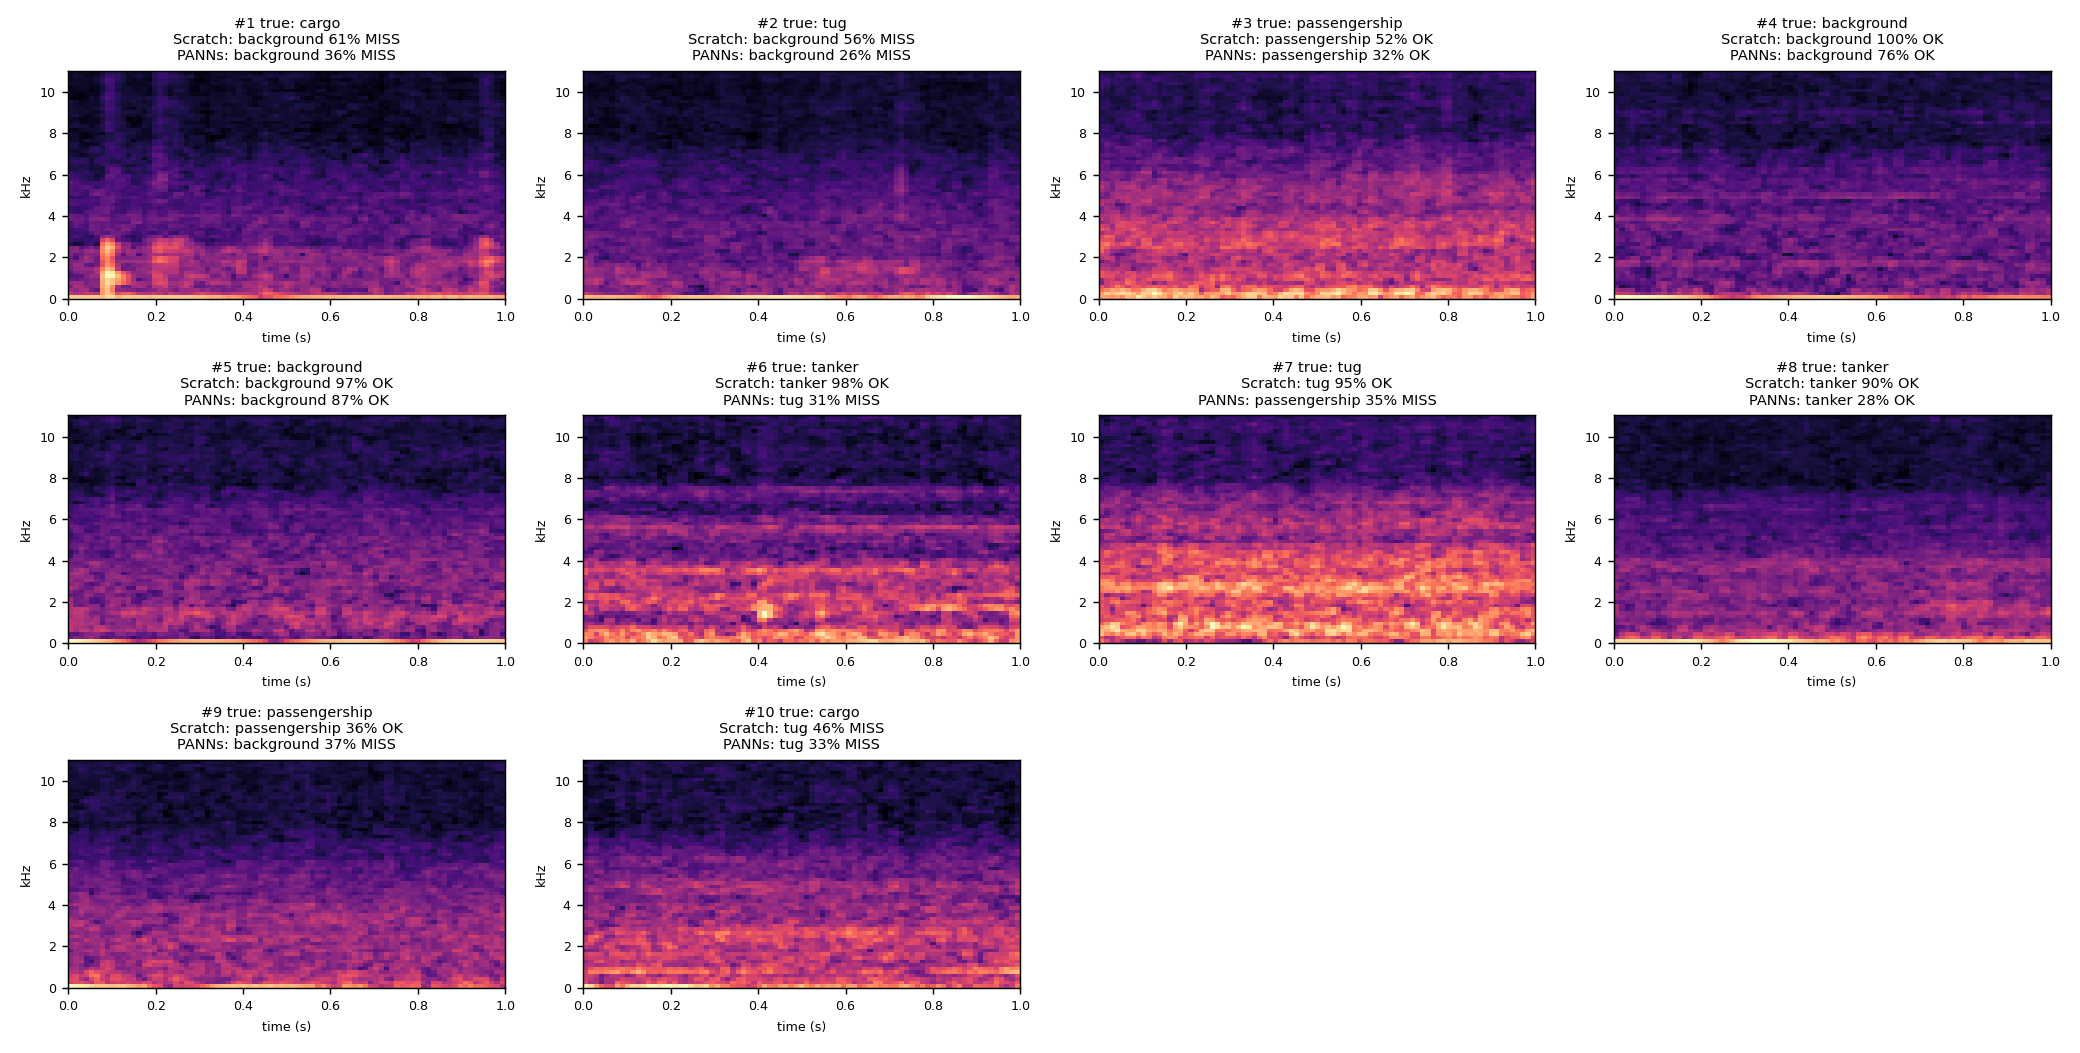

clip01_cargo.wav


clip02_tug.wav


clip03_passengership.wav


In [17]:
from IPython.display import Image, Audio, display
import glob
display(Image("demo_output/demo_spectrograms.png"))
for f in sorted(glob.glob("demo_output/clips/*.wav"))[:3]:
    print(f.split("/")[-1]); display(Audio(f))